In [3]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

#from gauss_slicer import * 

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [4]:
#import data
sparkles_cube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/sparkles_sweep.fits')

In [5]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 0
grating_freq = 15

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle) 

In [76]:
from scipy.optimize import curve_fit

def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    new_data = data.copy()

    mid = np.argmax(new_data)
    first_derivative = np.gradient(new_data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        new_data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        new_data[right_valley:len(new_data)] = 0
        #print(right_valley)

    return new_data


def mu(data):
    isolated = isolate_gaussian(data)
    x = np.arange(len(data))
    popt = curve_fit(gauss,x,isolated,p0=[np.argmax(data),2])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return mu, sigma, fwhm
    

def slice_speckle_angle(img,speckle_number,print_updates=False):
    #locate the general area of the speckle
    extent=20
    speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
    speckle_center = speckle_coords[speckle_number]

    #cut out the speckle area
    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-grating_angle))(img.grid)
    speckle_img = rect * img

    #find the center of intensity of the speckle area and window the image around that center
    center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
    window_size=40
    new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)
    
    shaped = new_img.shaped
    mus = np.zeros(shaped.shape[0])

    snr_threshold = 2

    for i in range(shaped.shape[0]): #in np.array([40,0]):
        if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
            sliced = shaped[:,i]
        else: sliced = shaped[i,:]

        zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)

        if zscore > snr_threshold:
            s = isolate_gaussian(sliced)
            s /= s.max()
            m, std, fwhm = mu(s)
            mus[i] = m
        else: mus[i] = -1

    deriv2 = np.gradient(np.gradient(mus))

    nonlin_region = np.atleast_1d(np.squeeze(np.where(np.abs(deriv2) >= 0.4)))

    midpoint = int(np.floor(window_size / 2))
    leftbound = nonlin_region[nonlin_region < midpoint][-1] if any(nonlin_region < midpoint) else None
    rightbound = nonlin_region[nonlin_region > midpoint][0] if any(nonlin_region > midpoint) else None

    if leftbound is not None and rightbound is not None:
        linear_region = mus[leftbound:rightbound]
        lin_x = np.arange(len(linear_region))

        m , b = np.polyfit(lin_x,linear_region,deg=1)
        angle = np.arctan(m)
        if print_updates ==True:
            print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')

        return np.degrees(angle)
    else: 
        if print_updates == True:
            print(f'unable to fit speckle {speckle_number}')
        return np.nan


#now find the speckle angles for all four 
def all_speckle_angles(img):
    angles = np.zeros(4)
    for i in range(4):
        #print(i)
        angles[i] = slice_speckle_angle(img,i)
    return angles

In [31]:
#filter all the image cubes from each step
img_cube = [] #filtered image cube at each step
diffs13_list = [] #list of speckle pair differences for each step
diffs24_list = []
angles_list = [] 


for i, field in enumerate(sparkles_cube):
    filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=10)) 
    #imshow_field(filtered)
    #filtered = Field(np.array([x if x > 0 else 0 for x in filtered ]),filtered.grid)
    img_cube.append(filtered)
    a = all_speckle_angles(filtered)
    angles_list.append(a)
    diffs13_list.append(a[0] - a[2])
    diffs24_list.append(a[1] - a[3])


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_76560/314129785.py:4: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )
/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_76560/314129785.py:31: OptimizeWarning: Covariance of the parameters could not be estimated
  popt = curve_fit(gauss,x,isolated,p0=[np.argmax(data),2])
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/scipy/optimize/_minpack_py.py:497: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


In [ ]:
print(angles_list[100])
print(a)
print()

[  0.4691729   13.6757692   -2.13866901 -13.04540495]
[ 1.95901315 -7.09205494 -2.71774464  6.05881318]


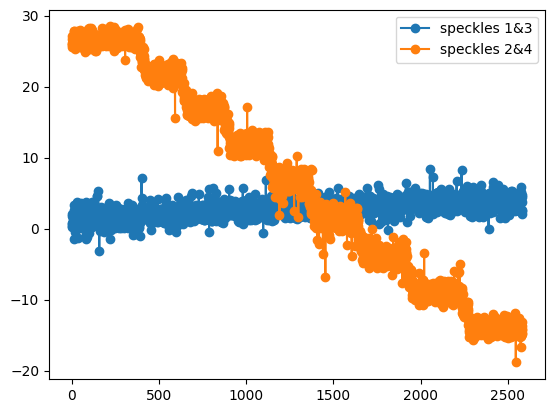

In [39]:
diffs13 = np.array(diffs13_list)
diffs24 = np.array(diffs24_list)

plt.plot(diffs13,'-o',label='speckles 1&3')
plt.plot(diffs24,'-o',label='speckles 2&4')
plt.legend()

In [77]:
#ok what if we use exactly the same image dataset but now measure the DM speckles instead of the sparkles
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle) 

img_cube_dm = [] #filtered image cube at each step
diffs13_list_dm = [] #list of speckle pair differences for each step
diffs24_list_dm = []
angles_list_dm = [] 


for i, field in enumerate(sparkles_cube):
    filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=60)) 
    #imshow_field(filtered)
    #filtered = Field(np.array([x if x > 0 else 0 for x in filtered ]),filtered.grid)
    img_cube_dm.append(filtered)
    a = all_speckle_angles(filtered)
    angles_list_dm.append(a)
    diffs13_list_dm.append(a[0] - a[2])
    diffs24_list_dm.append(a[1] - a[3])


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_76560/3343481614.py:4: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


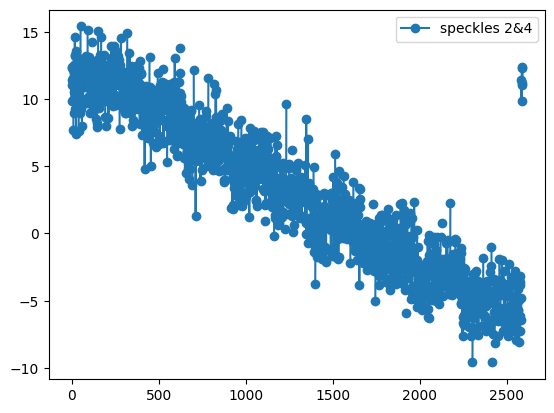

In [104]:
diffs13_dm = np.array(diffs13_list_dm)
diffs24_dm = np.array(diffs24_list_dm)

#plt.plot(diffs13_dm,'-o',label='speckles 1&3')
plt.plot(diffs24_dm,'-o',label='speckles 2&4')
plt.legend()

In [124]:
#let's try it on a truncated version so we don't have to wait 20 minutes to realize we did it wrong this time
#we already filtered so no sense in doing that again

diffs13_list_dm1 = [] 
diffs24_list_dm1 = []
angles_list_dm1 = [] 

for i, filtered in enumerate(img_cube_dm[0:50]):
    #filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=60)) 
    a = all_speckle_angles(filtered)
    angles_list_dm1.append(a)
    diffs13_list_dm1.append(a[0] - a[2])
    diffs24_list_dm1.append(a[1] - a[3])


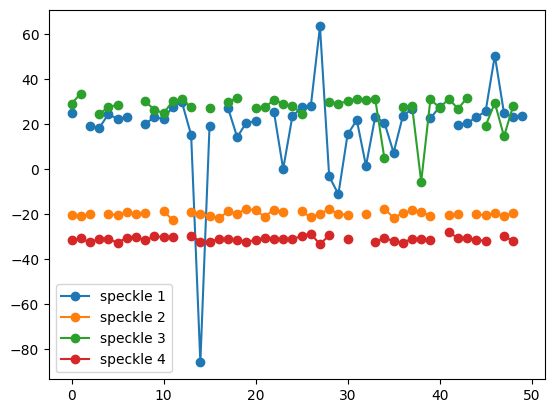

In [125]:
angles_arr = np.array(angles_list_dm1)

plt.plot(angles_arr[:,0],'-o',label='speckle 1')
plt.plot(angles_arr[:,1],'-o',label='speckle 2')
plt.plot(angles_arr[:,2],'-o',label='speckle 3')
plt.plot(angles_arr[:,3],'-o',label='speckle 4')
plt.legend()
plt.show()

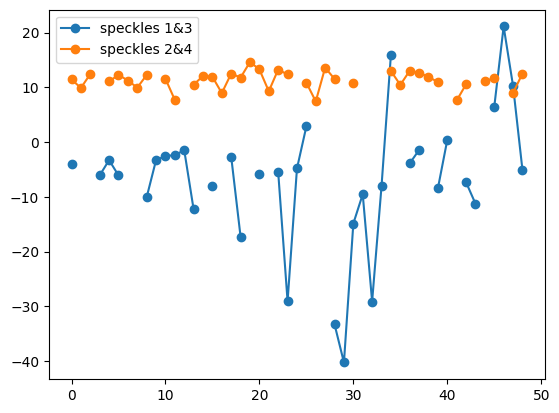

In [126]:
diffs13_dm1 = np.array(diffs13_list_dm1)
diffs24_dm1 = np.array(diffs24_list_dm1)

plt.plot(diffs13_dm1,'-o',label='speckles 1&3')
plt.plot(diffs24_dm1,'-o',label='speckles 2&4')
plt.legend()

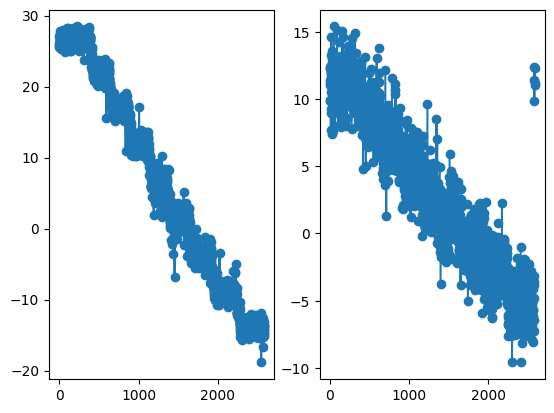

In [218]:
#let's look at side by side behavior of the sparkles and speckles
fig, ax = plt.subplots(1,2)
ax[0].plot(diffs24,'-o',label='vertical sparkles')
ax[1].plot(diffs24_dm,'-o',label='DM speckles 2&4')


In [234]:
#would be cool to add the FWHMs to that figure as well, so we can see all three
def fwhm(data):
    isolated = isolate_gaussian(data)
    x = np.arange(40)
    popt = curve_fit(gauss,x,isolated,p0 = [20,4])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return fwhm, mu, sigma

filtered_cube = []

for i, field in enumerate(sparkles_cube):
    filtered = ADC.crop_image(field,mask_diam=0) 
    filtered_cube.append(filtered)

widths = []

for img in filtered_cube:
    peak = np.argmax(img)
    window_center = img.grid.points[peak]

    pup = ADC.window_field(img,window_center,40,40)
    slice_column = np.array(np.unravel_index(np.argmax(pup),(40,40)))[0]
    slice = pup.shaped[:,slice_column]

    width, mean, sd = fwhm(slice)
    widths.append(width)

widths = np.array(widths)

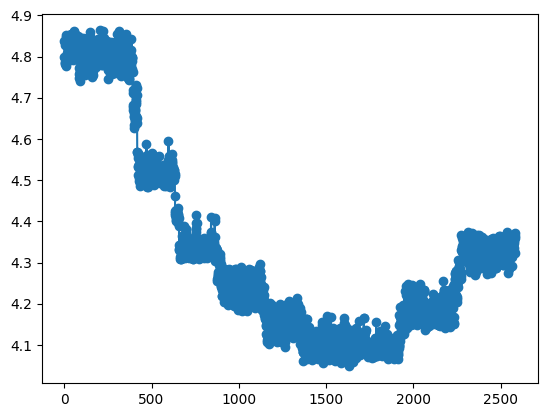

In [235]:
plt.plot(widths,'-o')

In [219]:
#ok now i gotta divvy everything into steps and make a pretty summary plot for my slide this week
step1s = 0
step1e = 375

step2s = 420
step2e = 630

step3s = 660
step3e = 860

step4s = 900
step4e = 1120

step5s = 1150
step5e = 1350

step6s = 1370
step6e = 1650

step7s = 1650
step7e = 1900

step8s = 1950
step8e = 2240

step9s = 2300
step9e = 2800


In [232]:
print(widths[step1s:step1e])

KeyError: slice(0, 375, None)

In [236]:
arrs = [diffs24,diffs24_dm,widths]
steps = []
for i,arr in enumerate(arrs):
    arr_step = []
    arr_step.append(arr[step1s:step1e])
    arr_step.append(arr[step2s:step2e])
    arr_step.append(arr[step3s:step3e])
    arr_step.append(arr[step4s:step4e])
    arr_step.append(arr[step5s:step5e])
    arr_step.append(arr[step6s:step6e])
    arr_step.append(arr[step7s:step7e])
    arr_step.append(arr[step8s:step8e])
    arr_step.append(arr[step9s:step9e])
    steps.append(arr_step)


In [ ]:
#filter the NaNs from the DM speckle array

for i in range(9):
    x = steps[1][i]
    steps[1][i] = x[~np.isnan(x)]


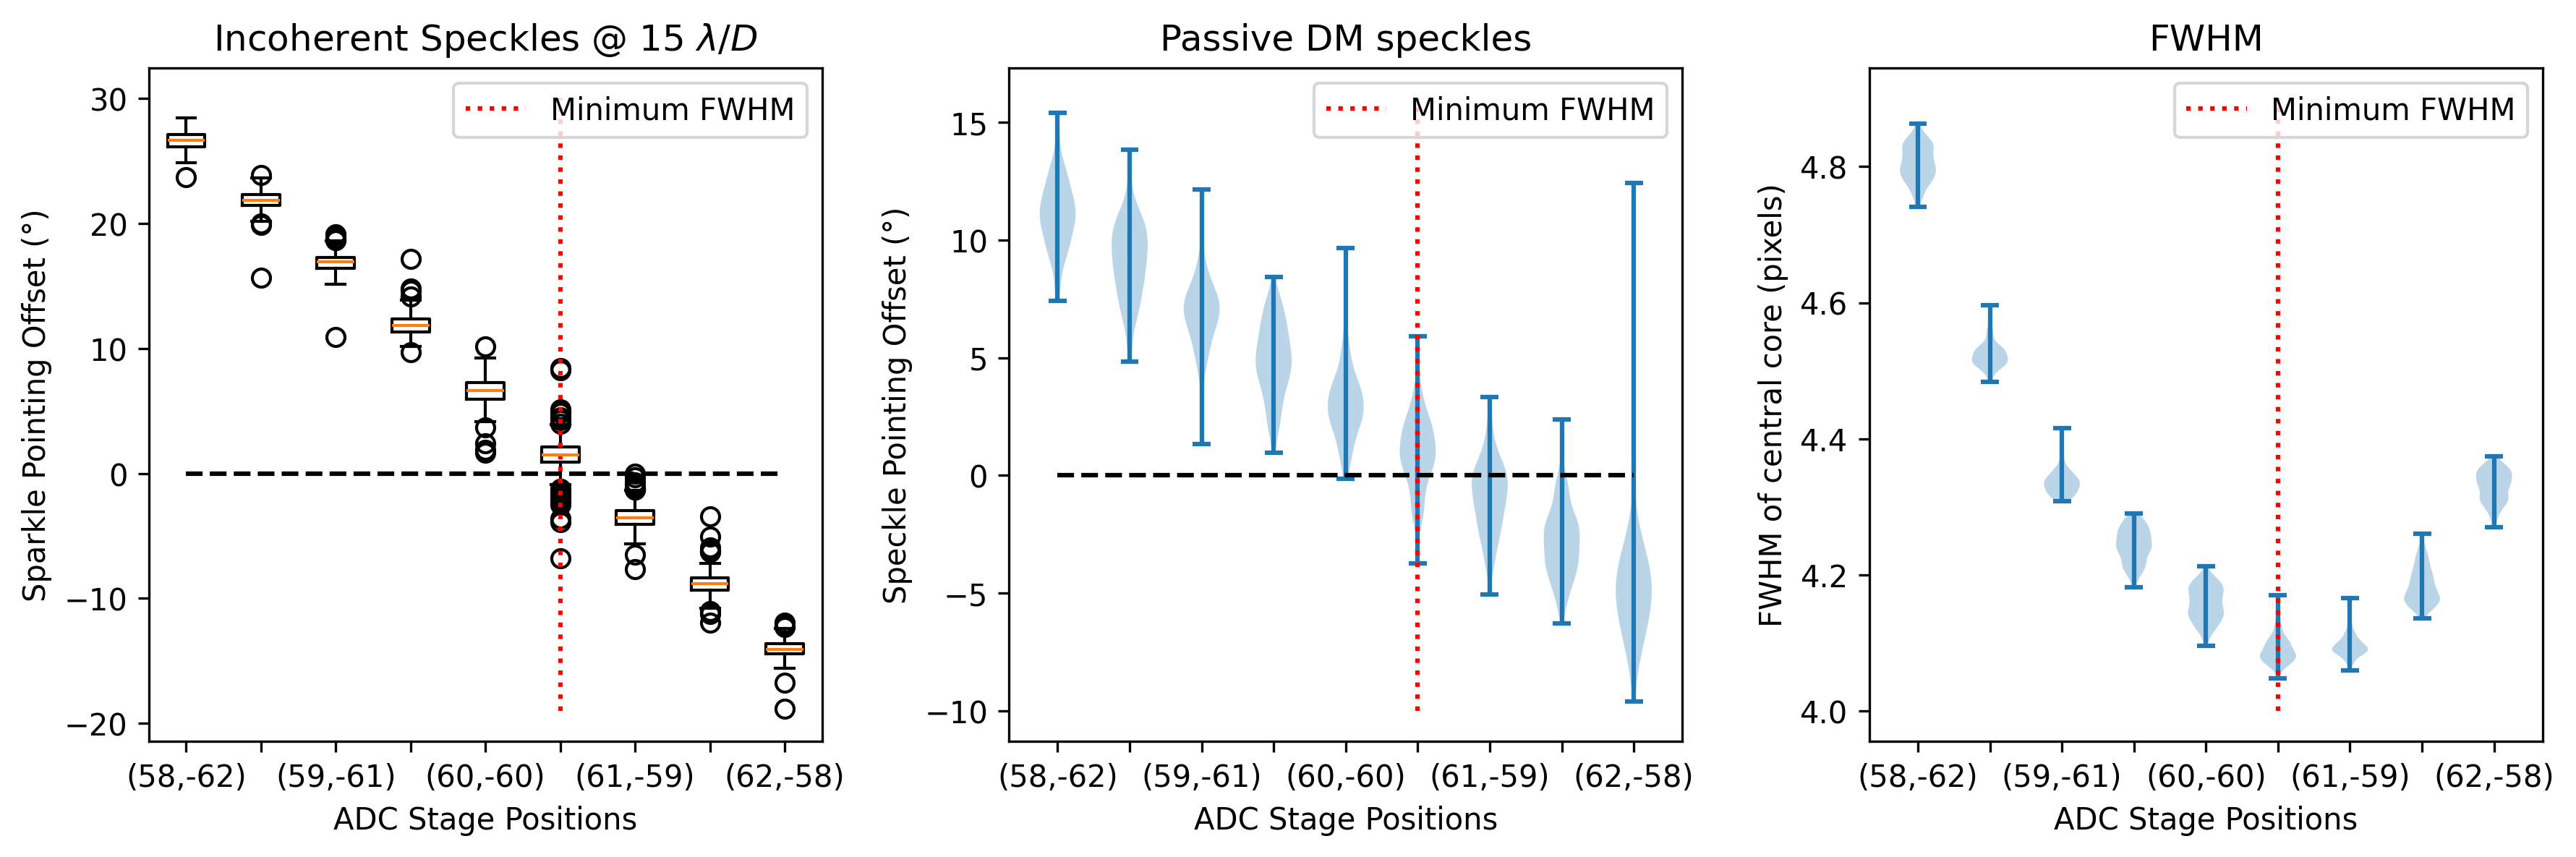

In [305]:
#violin plot time
seq = np.arange(1,10,step=1)
#xlabels = ['(58,-62)','(58.5,-61.5)','(59,-61)','(59.5,-60.5)','(60,-60)','(60.5,-59.5)','(61,-59)','(61.5,-58.5)','(62,-58)']
xlabels = ['(58,-62)','','(59,-61)','','(60,-60)','','(61,-59)','','(62,-58)']

fig, ax = plt.subplots(1,3,figsize=(12,4),dpi=300)

sparkles = ax[0].boxplot(steps[0])
ax[0].set_xticks(seq,xlabels,rotation=0)
ax[0].hlines(0,1,9,'black',linestyles='dashed')
ax[0].set_title(r'Incoherent Speckles @ 15 $\lambda /D$')
ax[0].set_box_aspect(1)
ax[0].set_xlabel('ADC Stage Positions')
ax[0].set_ylabel('Sparkle Pointing Offset (°)')
ax[0].vlines(6,-19,30,'red',linestyles='dotted',label='Minimum FWHM')
ax[0].legend()

speckles = ax[1].violinplot(steps[1])
ax[1].set_title('Passive DM speckles')
ax[1].set_xticks(seq,xlabels,rotation=0)
ax[1].hlines(0,1,9,'black',linestyles='dashed')
ax[1].set_box_aspect(1)
ax[1].set_xlabel('ADC Stage Positions')
ax[1].set_ylabel('Speckle Pointing Offset (°)')
ax[1].vlines(6,-10,16,'red',linestyles='dotted',label='Minimum FWHM')
ax[1].legend()

widths = ax[2].violinplot(steps[2])
ax[2].set_title('FWHM')
ax[2].set_xticks(seq,xlabels,rotation=0)
ax[2].set_box_aspect(1)
ax[2].set_xlabel('ADC Stage Positions')
ax[2].set_ylabel('FWHM of central core (pixels)')
ax[2].vlines(6,4,4.9,'red',linestyles='dotted',label='Minimum FWHM')
ax[2].legend()

plt.tight_layout()
plt.show()